# Ramawa Naphtal Junior
# Data Science 500 Assignment
# -------------------------------------------------------------------------------------------
## 1. Importing libraries needed for assignment

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Web scraping
import requests
from bs4 import BeautifulSoup

# Visualisation

# Installing matplotlibrary since it was not installed on student's laptop
!pip install matplotlib 

import matplotlib.pyplot as plt  #importing matplotlib library as plt

import warnings
warnings.filterwarnings('ignore')



## 2. Data acqusition and Web scrapping

In [2]:
base_url1 = "https://books.toscrape.com/"
response = requests.get(base_url1, timeout=15) #"Go to this website and bring back its HTML."
print(response.status_code)  #check whether Python successfully connected to the website.


200


In [3]:
base_url = "https://books.toscrape.com/catalogue/page-{}.html" #url template for multiple pages
site_url = "https://books.toscrape.com/catalogue/"

books = []

for page in range(1, 51):

    url = base_url.format(page)
    response = requests.get(url)

    if response.status_code != 200:
        continue

    soup = BeautifulSoup(response.text, "html.parser")

    book_containers = soup.find_all("article", class_="product_pod")

    for book in book_containers:

        title = book.h3.a["title"]

        price = book.find("p", class_="price_color").text
        price = float(price.replace("£", "").replace("Â", ""))

        rating = book.find("p")["class"][1]

        availability = book.find_all("p")[1].text.strip()

        # Get product page URL
        book_url = book.h3.a["href"]
        book_url = site_url + book_url.replace("../", "")

        # Open product page
        product_response = requests.get(book_url)
        product_soup = BeautifulSoup(product_response.text, "html.parser")

        # Extract genre from breadcrumb
        breadcrumb = product_soup.find("ul", class_="breadcrumb")
        genre = breadcrumb.find_all("a")[2].text.strip()

        books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability,
            "Genre": genre
        })

print(f"Books scraped: {len(books)}")

Books scraped: 1000


## 3. Create dataframe from books list

In [56]:
df = pd.DataFrame(books) #create dataframe from books list

display(df.head()) #display first five rows of dataframe

print("Dataset shape:", df.shape) #print the shape of the dataframe

,Title,Price,Rating,Availability,Genre
0,A Light in the Attic,51.77,Three,Â£51.77,Poetry
1,Tipping the Velvet,53.74,One,Â£53.74,Historical Fiction
2,Soumission,50.10,One,Â£50.10,Fiction
3,Sharp Objects,47.82,Four,Â£47.82,Mystery
4,Sapiens: A Brief History of Humankind,54.23,Five,Â£54.23,History


Dataset shape: (1000, 5)


## 4. Data Exploration
### 4.1. Inspect data

In [57]:
#display data types.
print(df.dtypes)

# display descriptive data
df.describe()

Title               str
Price           float64
Rating              str
Availability        str
Genre               str
dtype: object


,Price
count,1000.00000
mean,35.07035
std,14.44669
min,10.00000
25%,22.10750
50%,35.98000
75%,47.45750
max,59.99000


------------------------------------------------------------
#### Student REmarks: From above output
#### 1. Title is in correct data type of string.
#### 2. Price is in correct data type of a float.
#### 3. Rating is in INCORRECT data type of string instead of an integer
#### 4. Availibility is in correct data type of string.
#### 5. Genre is in correct data type of a string.
-------------------------------------------------------------------

### 4.2. Checking for missing values


In [58]:
df.isnull()

,Title,Price,Rating,Availability,Genre
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
995,False,False,False,False,False
996,False,False,False,False,False
997,False,False,False,False,False
998,False,False,False,False,False


In [59]:
# Check number of empty cells per column
df.isnull().sum()

Title           0
Price           0
Rating          0
Availability    0
Genre           0
dtype: int64

-----------------------------------------------------------------
#### Student remarks: From the above output, it is evident that there is no missing value in any of the cells' columns.
------------------------------------------------------------------

### 4.3. Checking for duplicate rows.


In [54]:
duplicates = df.duplicated().sum()
print("Number of duplicate rows: ", duplicates)

Number of duplicate rows:  0


--------------------------------------------------------------
#### Student Remarks: There is no duplicate rows in dataframe.
--------------------------------------------------------------

### 4.4. Correcting erroneous Data Types from 4.1

In [61]:
#Create rating_map function that chnges string ratings their integer equivalence
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}


print(df["Rating"].unique()) #Displaying unique values statement was used to debugg a code error.
df["Rating"] = df["Rating"].map(rating_map)  #Aplly the rating_map function into Rating column through the map() function.
df["Rating"]

<StringArray>
['Three', 'One', 'Four', 'Five', 'Two']
Length: 5, dtype: str


0      3
1      1
2      1
3      4
4      5
      ..
995    1
996    4
997    5
998    1
999    5
Name: Rating, Length: 1000, dtype: int64

In [62]:
# Convert price from string to numerical.
df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("£", "", regex=False)
    .str.replace("Â", "", regex=False)
)

df["Price"] = pd.to_numeric(df["Price"])

In [63]:
print(df.dtypes)

Title               str
Price           float64
Rating            int64
Availability        str
Genre               str
dtype: object


---------------------------
#### Student Remark: Rating data type has been changed to an integer
---------------------------

### 4.5. Check categorical values.
#### Only two categorical columns exist that need evaluation: Availability snd Genre column.

####
### 4.5.1 Availibility

In [64]:
print("Unique Availability Values:")

print(df["Availability"].unique()) #printing all unique availibility values.
print(df["Availability"].value_counts()) #printing total number of unique availibility values.

Unique Availability Values:
<StringArray>
['Â£51.77', 'Â£53.74', 'Â£50.10', 'Â£47.82', 'Â£54.23', 'Â£22.65', 'Â£33.34',
 'Â£17.93', 'Â£22.60', 'Â£52.15',
 ...
 'Â£41.24', 'Â£39.07', 'Â£29.82', 'Â£37.26', 'Â£20.30', 'Â£34.65', 'Â£43.38',
 'Â£57.06', 'Â£16.97', 'Â£26.08']
Length: 903, dtype: str
Availability
Â£44.18    3
Â£16.28    3
Â£37.34    3
Â£27.88    3
Â£39.24    3
          ..
Â£34.65    1
Â£43.38    1
Â£57.06    1
Â£16.97    1
Â£26.08    1
Name: count, Length: 903, dtype: int64


#### 4.5.2. Genre column

In [65]:
print("Unique Genres:")
print(df["Genre"].unique()) #printing number of unique genres.


print("Number of Genres:")
print(df["Genre"].nunique()) #printing number of genres.
print(df["Genre"].value_counts()) # printing number of genres per nominal category

Unique Genres:
<StringArray>
[            'Poetry', 'Historical Fiction',            'Fiction',
            'Mystery',            'History',        'Young Adult',
           'Business',            'Default',     'Sequential Art',
              'Music',    'Science Fiction',           'Politics',
             'Travel',           'Thriller',     'Food and Drink',
            'Romance',          'Childrens',         'Nonfiction',
                'Art',       'Spirituality',         'Philosophy',
          'New Adult',       'Contemporary',            'Fantasy',
      'Add a comment',            'Science',             'Health',
             'Horror',          'Self Help',           'Religion',
          'Christian',              'Crime',      'Autobiography',
  'Christian Fiction',          'Biography',     'Womens Fiction',
            'Erotica',           'Cultural',         'Psychology',
              'Humor',         'Historical',             'Novels',
      'Short Stories',           

###
### 4.6. Validating data
#### 4.6.1. Checking invalid prices (Negative prices)

In [66]:
invalid_prices = df[df["Price"] <= 0] #condition for prices less than 0

print("Invalid Prices:")
print(invalid_prices) #print the prices less than 0

Invalid Prices:
Empty DataFrame
Columns: [Title, Price, Rating, Availability, Genre]
Index: []


----------------
#### Student remarks: The results are an empty data frame denoting that there is no negative price.
-----------------

####

#### 4.6.2. Checking Ratings outside of 1-5 scale

In [67]:
invalid_ratings = df[ #getting ratings that are lower than 1 OR higher than 5, and storing them as invalid_ratings
    (df["Rating"] < 1) |
    (df["Rating"] > 5)
]

print("Invalid Ratings:")
print(invalid_ratings) #printing the invalid ratings

Invalid Ratings:
Empty DataFrame
Columns: [Title, Price, Rating, Availability, Genre]
Index: []


----------------
#### Student remarks: The results are an empty data frame all ratings are within the scale.
-----------------

#####

#### 4.6.3. Checking for inconsistent categories.

##

## 4.7. Checking Outliers

In [68]:
df.describe()
Q1 = df["Price"].quantile(0.25)

Q3 = df["Price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -15.91749999999999
Upper Bound: 85.48249999999999


------
#### Student Remarks: 
##### - The neagative lower bound suggests that there are no low-end outliers for the price since price cannot be lower than 0.
##### - The upper bound of 85.48 denotes that any price above 85.48 is an outlier in our set.
----------

In [69]:
outliers = df[   #get values that are outliers
    (df["Price"] < lower_bound) |
    (df["Price"] > upper_bound)
]

print("Number of Outliers:", len(outliers)) #printing the number of outliers

outliers.head() #printing first five rows of outlier set

Number of Outliers: 0


,Title,Price,Rating,Availability,Genre


------
#### Student Remarks: 
##### - The number of outliers from output is zero.
##### - That is futher proven by an empty head of the outlier dataframe.
----------

#


### 4.8. Box Plot

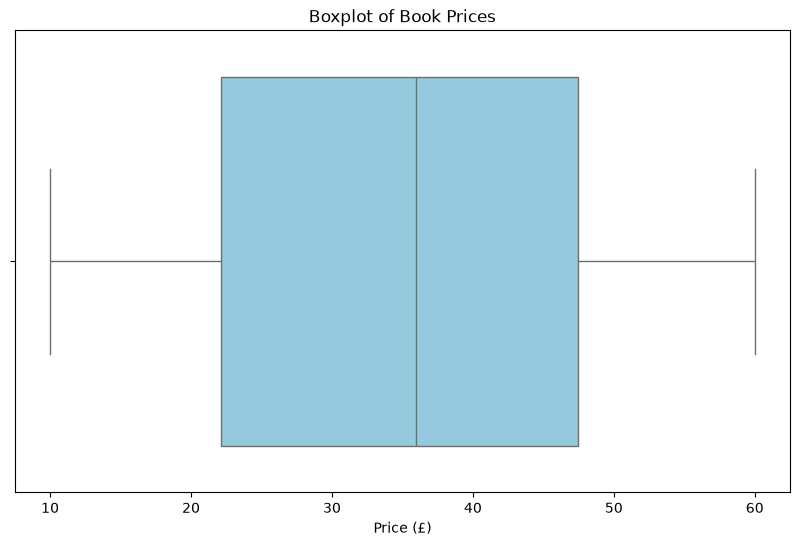

In [70]:
import matplotlib.pyplot as plt #import matyplotlib library

#Installing seaborn module since it wasn't previously installed on student computer beforehand.
!pip install seaborn
import seaborn as sns

plt.figure(figsize=(10,6))

sns.boxplot(
    x=df["Price"],
    color="skyblue"
)

plt.title("Boxplot of Book Prices")
plt.xlabel("Price (£)")

plt.show()

----
### Student remarks:
#### - The above shows a boxplot of the descriptive data of the book prices.
#### - It is evident that lowest book price is around 10, while book price is about 60 Euros.
#### - The mean price is about 35 Euros.
#### - The above box plot corresponds to the descriptive information generated by the describe() function
-----

## 4.9. Verify cleaned data

In [71]:
#printing final dataframe shape.
print("Final Dataset Shape:")
print(df.shape)

#printing final dataframe datatypes
print("Final Data Types:")
print(df.dtypes)

#Checking for final missing
print("Final Missing Values:")
print(df.isnull().sum())

#displaying first five rows of final dataframe.
df.head()

Final Dataset Shape:
(1000, 5)
Final Data Types:
Title               str
Price           float64
Rating            int64
Availability        str
Genre               str
dtype: object
Final Missing Values:
Title           0
Price           0
Rating          0
Availability    0
Genre           0
dtype: int64


,Title,Price,Rating,Availability,Genre
0,A Light in the Attic,51.77,3,Â£51.77,Poetry
1,Tipping the Velvet,53.74,1,Â£53.74,Historical Fiction
2,Soumission,50.10,1,Â£50.10,Fiction
3,Sharp Objects,47.82,4,Â£47.82,Mystery
4,Sapiens: A Brief History of Humankind,54.23,5,Â£54.23,History


### STudent remarks:
#### - Shape, datatypes, and datavalues are all in their correct formats.

#
#
# 5. Data Visualization and Exploration

In [76]:
#Summary of desriptive data of price
print("\nPrice Statistics:")
print(df["Price"].describe())

#Summary of descriptive data of RAting
print("\nRating Statistics:")
print(df["Rating"].describe())

# printing out mean, median, min, max, and standard deviation separately for price.
print("\nPrice Mean:", df["Price"].mean())
print("Price Median:", df["Price"].median())
print("Price Minimum:", df["Price"].min())
print("Price Maximum:", df["Price"].max())
print("Price Standard Deviation:", df["Price"].std())

# Printing out mean, median, standard deviation, max, and min of the Ratings column
print("\nRating Mean:", df["Rating"].mean())
print("Rating Median:", df["Rating"].median())
print("Rating Minimum:", df["Rating"].min())
print("Rating Maximum:", df["Rating"].max())
print("Rating Standard Deviation:", df["Rating"].std())


Price Statistics:
count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price, dtype: float64

Rating Statistics:
count    1000.000000
mean        2.923000
std         1.434967
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: Rating, dtype: float64

Price Mean: 35.07035
Price Median: 35.980000000000004
Price Minimum: 10.0
Price Maximum: 59.99
Price Standard Deviation: 14.446689669952764

Rating Mean: 2.923
Rating Median: 3.0
Rating Minimum: 1
Rating Maximum: 5
Rating Standard Deviation: 1.434966943915479


## 5.2. Visualization of book prices

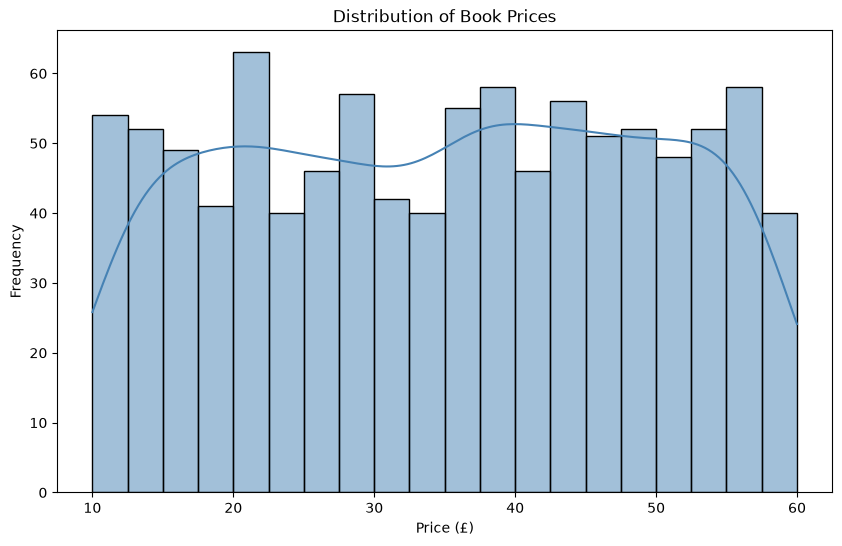

In [77]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["Price"],
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")

plt.show()

## 5.3. Visualization of book ratings.

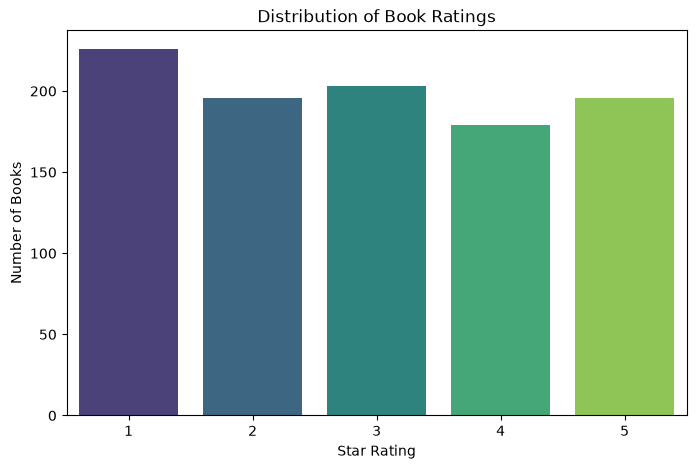

In [78]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Rating",
    data=df,
    palette="viridis"
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")

plt.show()

## 5.4. Countplot for book availibility VS inavailibility

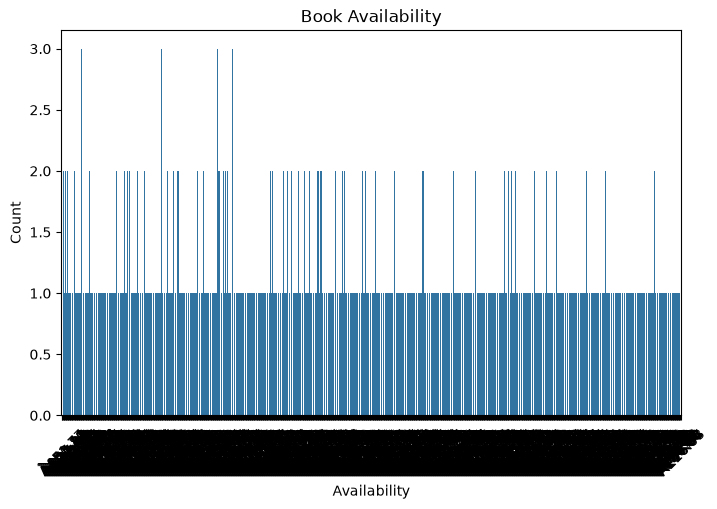

In [82]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Availability",
    data=df
)

plt.title("Book Availability")
plt.xlabel("Availability")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()


## 5.5. Bar Chart for book distribution across genres

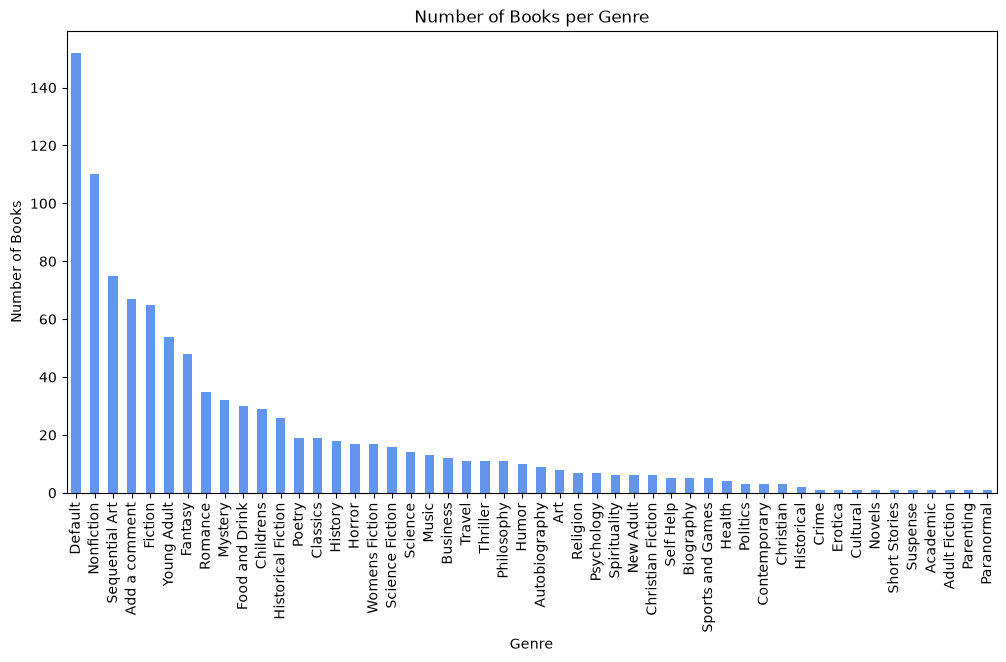

In [83]:
genre_counts = df["Genre"].value_counts()

plt.figure(figsize=(12,6))

genre_counts.plot(
    kind="bar",
    color="cornflowerblue"
)

plt.title("Number of Books per Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Books")

plt.xticks(rotation=90)

plt.show()

## 5.6. Bar Chart for average prices across genres

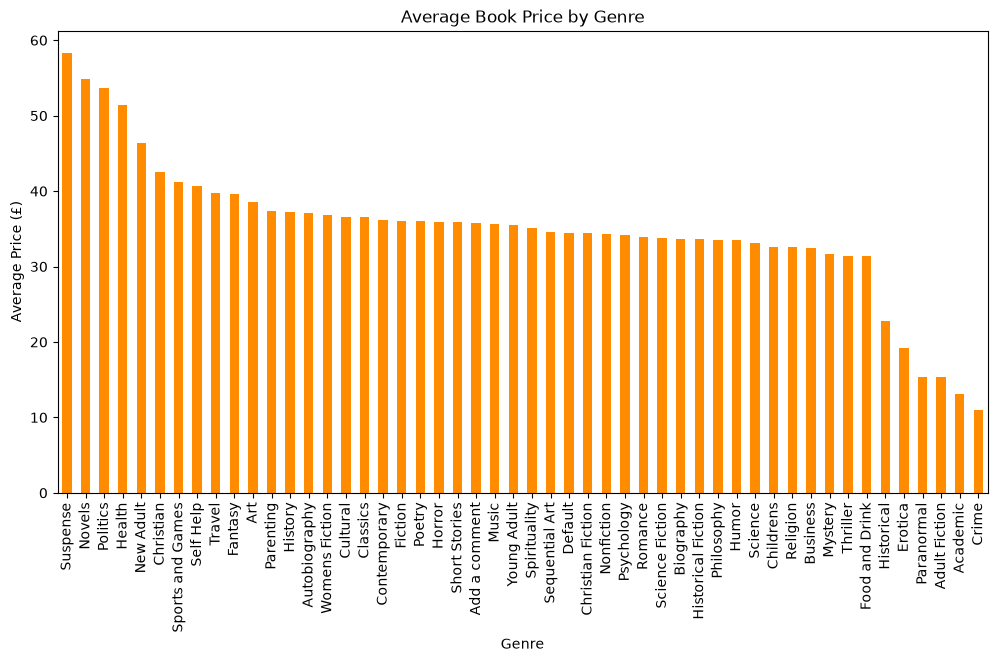

In [84]:
avg_genre_price = (
    df.groupby("Genre")["Price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))

avg_genre_price.plot(
    kind="bar",
    color="darkorange"
)

plt.title("Average Book Price by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Price (£)")

plt.xticks(rotation=90)

plt.show()

## 5.7. Bar Chart for Ratings across genres

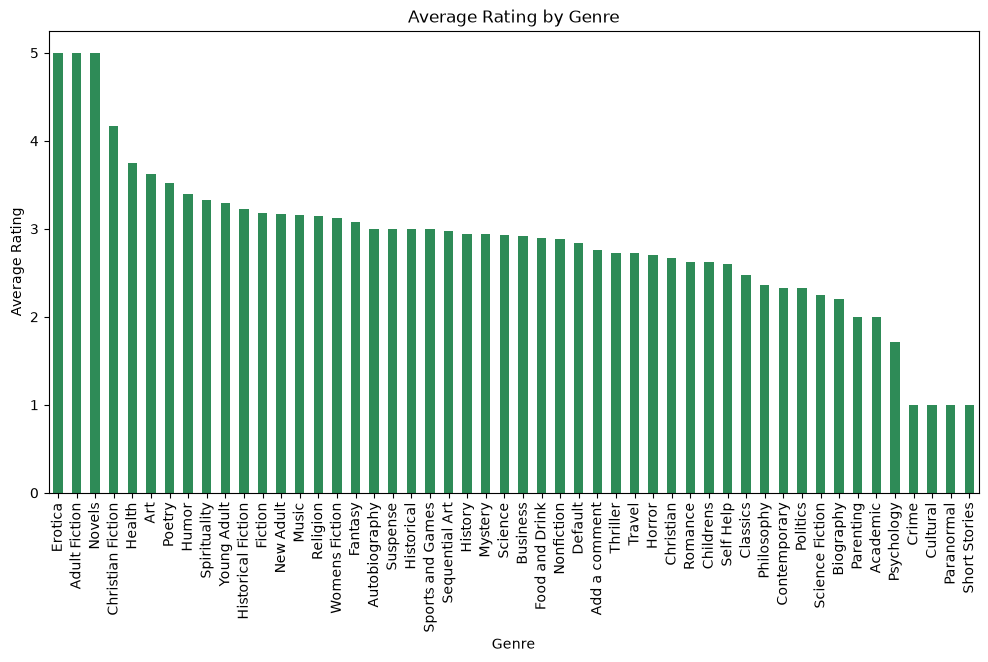

In [85]:
avg_genre_rating = (
    df.groupby("Genre")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))

avg_genre_rating.plot(
    kind="bar",
    color="seagreen"
)

plt.title("Average Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Rating")

plt.xticks(rotation=90)

plt.show()

## 5.8. Scatterplot for relationship between price and rating

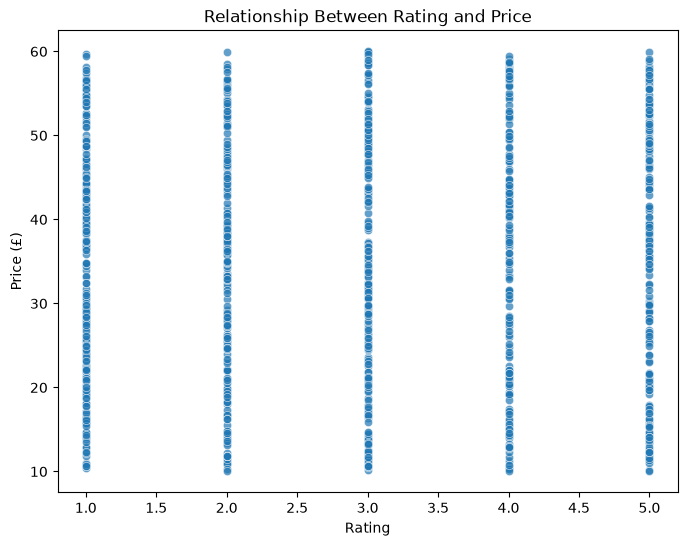

In [86]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="Rating",
    y="Price",
    alpha=0.7
)

plt.title("Relationship Between Rating and Price")
plt.xlabel("Rating")
plt.ylabel("Price (£)")

plt.show()

## 5.9. BoxPlot for price distribution across genres.

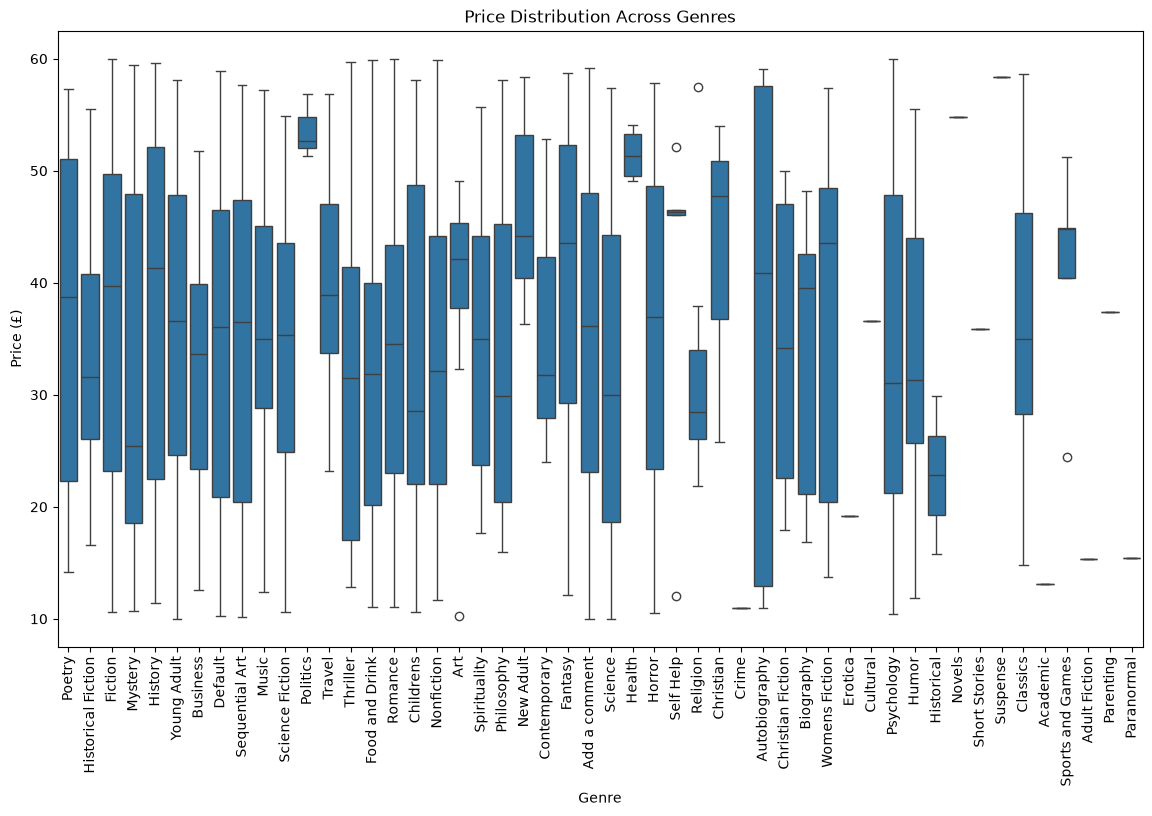

In [87]:
plt.figure(figsize=(14,8))

sns.boxplot(
    data=df,
    x="Genre",
    y="Price"
)

plt.title("Price Distribution Across Genres")
plt.xlabel("Genre")
plt.ylabel("Price (£)")

plt.xticks(rotation=90)

plt.show()

## 5.10. Correlation Analysis

             Price    Rating  In_Stock
Price     1.000000  0.028166       NaN
Rating    0.028166  1.000000       NaN
In_Stock       NaN       NaN       NaN


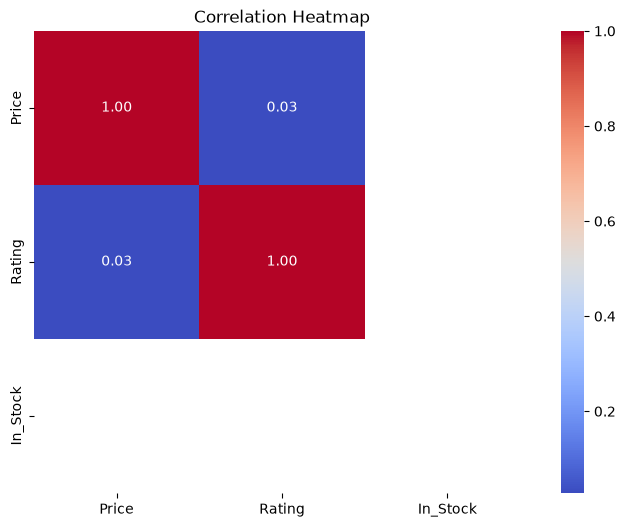

In [91]:
df["In_Stock"] = df["Availability"].apply(
    lambda x: 1 if "In stock" in str(x) else 0
)

corr_matrix = df[
    ["Price", "Rating", "In_Stock"]
].corr()

print(corr_matrix)

plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [94]:
print(df["In_Stock"].value_counts())
print("\n\nThe Number of unique value in stack avilibility is:", df["In_Stock"].nunique())

In_Stock
0    1000
Name: count, dtype: int64


The Number of unique value in stack avilibility is: 1


### Student remarks:
#### - The correlation matrix returns NAN for In_stock column because all books are in-stock(Availaible)
#### - This is further proven by the unique number function returning only one unique value in stock availibility.
#### - Therefore, All scraped books were listed as "In stock". Therefore, availability showed no variation and could not be used as a meaningful predictor in correlation analysis or predictive modelling.

## 6. Outputing final Dataframe to CSV file

In [108]:
!pip install openpyxl
df.to_excel("C:/Users/napht/Downloads/JuniorData.xlsx")


#
## 7. Interpreting visualizations

## Book Prices
#### - Highest book price was around 60 pounds while lowest book price was around 10 pounds.
#### - Book prices just around 20-22.5 pounds had high frequency of being bought.
#### - Books around prices, 17.5 - 20, 22.5 - 25, 32.5 -35, 58.5 - 60 had low frequencies of being bought.


## Book Ratings
#### - Over 200 books had a rating of one.
#### - Other ratings had around 150-200 books.



## Number of books per genre
#### - Default genre had highest number of books (above 140)
#### - Non-fictional was second with around 110 books availaible.
#### - Lowest availaoble genre is paranormal.



## Average prices across genre.
#### - Suspense, Novels, and politics amongst genres with highest prices.
#### - Low prices genres include audult fiction, Erotica, Paranomal, Academic, and Crime.



#
## 8. Summarize EDA findings

#### The exploratory data analysis revealed important trends within the book catalogue. Book prices were distributed across a moderate range with some high-priced outliers. The majority of books were concentrated within a few rating categories, indicating differences in popularity and perceived quality. Genre analysis showed that some genres contained considerably more books than others. Average prices varied across genres, suggesting that genre may influence pricing. The relationship between ratings and price appeared relatively weak, implying that higher-rated books are not necessarily more expensive. Correlation analysis confirmed that the numerical variables exhibited only weak to moderate relationships. 

#
## 9. Predictive Modelling using Linear Regression.

In [109]:
#importing Linear regression Libraries

In [113]:
#installing sklearn module
!pip install scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 365.2 kB/s eta 0:00:22
   -- ------------------------------------- 0.5/8.4 MB 365.2 kB/s eta 0:00:22
   -- ------------------------------------- 0.5/8.4 MB 365.2 kB/s eta 0:00:22
   -- -

In [115]:
#Predictive model with encoded genres

In [117]:
genre_dummies = pd.get_dummies(df["Genre"], drop_first=True)

X = pd.concat(
    [df[["Rating"]], genre_dummies],
    axis=1
)

y = df["Price"]

In [118]:
#Data split intyo training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [119]:
#Checking sizes of training and testing set data
print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (800, 50)
Testing Set: (200, 50)


In [120]:
#Creating and Training Model
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [121]:
#Making predictions and outputing prediction values.
y_pred = model.predict(X_test)
print(y_pred[:10])

[34.21703616 34.35740167 31.22347766 34.27278886 33.76658936 32.70318087
 34.35740167 34.58262507 36.96017364 34.3326152 ]


In [122]:
#Compare actual Data with predictions
comparison_df = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison_df.head(10)

,Actual Price,Predicted Price
0,11.38,34.217036
1,20.93,34.357402
2,33.92,31.223478
3,48.39,34.272789
4,20.50,33.766589
5,26.77,32.703181
6,16.96,34.357402
7,20.90,34.582625
8,36.17,36.960174
9,24.12,34.332615


In [123]:
# Evaluating model performance

In [124]:
#MAE
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2))

Mean Absolute Error: 13.01


In [125]:
#MSE
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", round(mse, 2))

Mean Squared Error: 231.02


In [126]:
#RMSE
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", round(rmse, 2))

Root Mean Squared Error: 15.2


In [127]:
#Root square score between test values nad prediction values.
r2 = r2_score(y_test, y_pred)

print("R2 Score:", round(r2, 4))

R2 Score: -0.0998


In [128]:
#Compare training and testing performance

In [129]:
#Training Score
train_score = model.score(
    X_train,
    y_train
)

print("Training R2:", round(train_score, 4))


Training R2: 0.0592


In [130]:
#Testing score
test_score = model.score(
    X_test,
    y_test
)

print("Testing R2:", round(test_score, 4))

Testing R2: -0.0998


In [131]:
#Comparison

In [132]:
print("Training R2 =", round(train_score,4))
print("Testing R2  =", round(test_score,4))

Training R2 = 0.0592
Testing R2  = -0.0998


In [133]:
#Visualize Actual VS Predicted prices

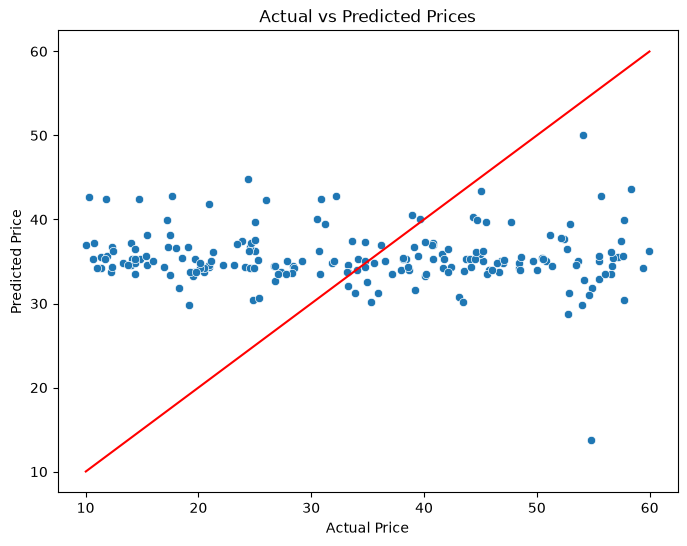

In [134]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

sns.scatterplot(
    x=y_test,
    y=y_pred
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")

plt.show()


In [135]:
#Examine model coefficient

In [136]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 12.669553203686956
Coefficient: 0.2252233981563511


##
## Interpretation of model

## 1. How accurately Linear Regression predicted book prices

The model was not very accurate. The scatter plot shows that most predicted prices are clustered between approximately £30 and £40, regardless of the actual price. Ideally, the points should lie close to the red diagonal line, which represents perfect predictions.

Instead, many points are far from the line. For example:

Books with actual prices around £10-20 are often predicted around £35.
Books with actual prices around £55-60 are also predicted around £35.

This indicates that the model tends to predict an "average" price rather than accurately estimating individual book prices.

Furthermore, the:

Training R² = 0.0592
Testing R² = -0.0998

show that the model explains almost none of the variation in book prices.

## 2. Difference in training and testing performance.

There was a difference between training and testing performance.

Metric	ValueTraining R2 was =	0.0592
Testing R2 was =	-0.0998

The training score is already very low, meaning the model learned very little from the training data.

The testing score is negative, which is even worse. A negative R² means the model performs worse than simply predicting the average book price for every observation.

Interpretation

The model does not generalise well to unseen data. However, this is not an overfitting problem because:

Training performance is poor.
Testing performance is poor.

This situation is called underfitting. The model is too simple to capture the factors influencing book prices.

## 3. What the residual plot revealed

I did not draw the residual plot, howerver, the Actual vs Predicted scatter plot allows us to infer the residual pattern.

The residuals appear to be large and widely spread.

Evidence:

Low-priced books are often overestimated.
High-priced books are often underestimated.
Predictions are concentrated around £35.

This suggests systematic prediction errors rather than random noise.

A residual plot would likely show:

Large residual values.
No clear random pattern around zero.
Evidence that the model fails to capture important relationships in the data.

These observations indicate that the assumptions of a well-fitting linear model are not fully satisfied.

## 4. Why the model might struggle to predict prices

Several reasons explain the poor performance.

a) Too Few Features

From the coefficient output:

Intercept = 12.67
Coefficient = 0.225

Only Rating was used as a predictor.

The model tries to estimate book price solely from its star rating.

However, book prices are unlikely to depend only on ratings.

Other important factors include:

- Genre
- Book category
- Stock level
- Title characteristics
- Product popularity
- Publisher-related factors
b) Weak Relationship Between Rating and Price

The coefficient: 0.225 means that increasing the rating by one star increases the predicted price by only about 0.23 Pounds.

This is a very small effect.

Therefore, ratings provide very little information about price.

c) Real Prices May Not Follow a Linear Relationship

Book prices may be influenced by complex factors that do not have a simple linear relationship.

Linear Regression assumes a linear equation of y = mx +c, but real-world pricing is often much more complicated.

d) Missing Genre Information in the Model

Your EDA likely showed differences between genres.

For example:

Travel books may have different average prices from Poetry books.
Historical Fiction may differ from Sequential Art.

Ignoring genre removes valuable predictive information.

Overall Conclusion

The Linear Regression model performed poorly, achieving a Training R2 of 0.0592 and a Testing R² of -0.0998. The model was unable to accurately predict book prices and tended to predict values close to the overall average price. The scatter plot revealed substantial differences between actual and predicted prices, indicating large prediction errors. The main reason for the poor performance is that rating alone is a weak predictor of book price. Additional variables such as genre, stock information and other book characteristics should be included to improve predictive accuracy. The results suggest that book pricing is influenced by factors beyond star ratings, making a simple linear regression model insufficient for precise price prediction.